# PhonoLens · Notebook 1: Data, Classical Pipeline & Baseline
**Mispronunciation Detection and Articulatory Feedback for Indian English Speakers** · MAI522 SPR CIA-III, Team 23

This notebook:
- **A. Data:** loads L2-ARCTIC, makes speaker-independent splits, and analyses which sounds Hindi-L1 speakers mispronounce
- **B. Classical pipeline:** pre-emphasis, energy/ZCR VAD, pYIN pitch and our own LPC formant tracker, validated against Praat
- **C. Baseline:** the pretrained wav2vec2 phoneme recogniser (no fine-tuning), measured with PER and MDD precision/recall/F1
- **D. Vowel chart:** Hindi-L1 vowels vs other speakers, using CTC forced alignment and LPC formants

**How to run**
1. Runtime → Change runtime type → **T4 GPU**.
2. Run **cell 1**. The runtime restarts itself at the end; that's expected.
3. Then use Runtime → **Run all** (cell 1 is safe to re-run; it only restarts when the install changes something), or run cells 2 onward in order.

All figures and results are saved to `MyDrive/phonolens_data/figures` and `.../results` for the report.

In [1]:
# Cell 1: install (the runtime restarts once at the end; then run the rest)
import os
need_restart = False
try:
    import datasets
    need_restart = not datasets.__version__.startswith(("2.", "3."))
except ImportError:
    need_restart = True
!pip install -q "datasets>=2.19,<4" librosa soundfile praat-parselmouth g2p_en
if need_restart:
    print("Restarting runtime so the pinned `datasets` version loads. Run the next cells after this.")
    os.kill(os.getpid(), 9)
else:
    print("Packages ready ✅")

Packages ready ✅


In [2]:
# Cell 2: Drive, paths, local copy of the data, GPU check
import os, json, shutil, time
from google.colab import drive
drive.mount('/content/drive')

SAVE      = "/content/drive/MyDrive/phonolens_data"
LOCAL     = "/content/data"
MODEL_DIR = f"{SAVE}/models/wav2vec2-xlsr-53-espeak-cv-ft"
FIG, RES  = f"{SAVE}/figures", f"{SAVE}/results"
for d in (FIG, RES, LOCAL):
    os.makedirs(d, exist_ok=True)

# Reading from Drive during compute is slow, so copy to the local disk first.
for name in ["l2arctic"]:
    if not os.path.exists(f"{LOCAL}/{name}"):
        t = time.time()
        shutil.copytree(f"{SAVE}/{name}", f"{LOCAL}/{name}")
        print(f"copied {name} in {time.time()-t:.0f}s")

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda"
      else "CPU only. Part C will be slow: switch to a T4 GPU runtime.")

Mounted at /content/drive
copied l2arctic in 16s
Device: Tesla T4


In [3]:
%%writefile /content/drive/MyDrive/phonolens_data/phonolens_core.py
"""
phonolens_core.py — shared code for the PhonoLens project.

Sections
  1. Phone set (CMU-39 written in IPA) + normalisation of any IPA / ARPAbet input
  2. Alignment (Levenshtein) + mispronunciation detection & diagnosis (MDD) metrics
  3. CTC helpers: greedy decoding, Viterbi forced alignment
  4. Classical speech processing: pre-emphasis, framing, VAD, LPC (Levinson-Durbin), formants
  5. Feedback text for common Indian-English substitutions
"""
from collections import Counter
import numpy as np

# =============================================================================
# 1. PHONE SET
# =============================================================================
# CMU ARPAbet 39-phone set (the one L2-ARCTIC and speechocean762 are labelled in),
# written in IPA so it matches the L2-ARCTIC 'ipa' / 'g2p' columns.
ARPA2IPA = {
    "AA": "ɑ", "AE": "æ", "AH": "ʌ", "AO": "ɔ", "AW": "aʊ", "AY": "aɪ", "EH": "ɛ",
    "ER": "ɝ", "EY": "eɪ", "IH": "ɪ", "IY": "i", "OW": "oʊ", "OY": "ɔɪ", "UH": "ʊ",
    "UW": "u", "B": "b", "CH": "tʃ", "D": "d", "DH": "ð", "F": "f", "G": "ɡ",
    "HH": "h", "JH": "dʒ", "K": "k", "L": "l", "M": "m", "N": "n", "NG": "ŋ",
    "P": "p", "R": "ɹ", "S": "s", "SH": "ʃ", "T": "t", "TH": "θ", "V": "v",
    "W": "w", "Y": "j", "Z": "z", "ZH": "ʒ",
}
PHONES = sorted(set(ARPA2IPA.values()))                     # 39 phones
VOWELS = {"ɑ", "æ", "ʌ", "ɔ", "aʊ", "aɪ", "ɛ", "ɝ", "eɪ", "ɪ", "i", "oʊ", "ɔɪ", "ʊ", "u"}
MONOPHTHONGS = VOWELS - {"aʊ", "aɪ", "eɪ", "oʊ", "ɔɪ"}

# Marks we throw away (stress, length, tones, most diacritics, syllabicity, ties).
_STRIP = set("ˈˌːˑ̩̯̃ʰʲʷ̥̬̪̺̻͡‿.|-_ ") | {"̩", "̯", "̃", "͡", "˞"}

# Symbol rewrites applied before tokenising. Order matters (longest first).
# Several of these are deliberate accent-fairness decisions: e.g. Indian-English
# monophthongs [e:] / [o:] are mapped onto the FACE / GOAT diphthongs, and a tapped
# or trilled r is mapped onto /ɹ/, so these accent features are NOT counted as errors.
_REWRITES = [
    ("ɝɹ", "ɝ"), ("ɚɹ", "ɝ"), ("ɜɹ", "ɝ"), ("əɹ", "ɝ"),
    ("əʊ", "oʊ"), ("eə", "ɛ"), ("ɪə", "ɪ"), ("ʊə", "ʊ"), ("aɪə", "aɪ"),
    ("ɚ", "ɝ"), ("ɜ", "ɝ"), ("ə", "ʌ"), ("ɐ", "ʌ"), ("ᵻ", "ɪ"), ("ɨ", "ɪ"),
    ("ʉ", "u"), ("ɯ", "u"), ("y", "i"), ("ɒ", "ɑ"), ("ɫ", "l"), ("g", "ɡ"),
    ("ɾ", "ɹ"), ("r", "ɹ"), ("ɻ", "ɹ"), ("ʀ", "ɹ"), ("ʁ", "ɹ"),
    ("ʈ", "t"), ("ɖ", "d"), ("ɳ", "n"), ("ɭ", "l"), ("ʂ", "ʃ"), ("ɕ", "ʃ"), ("ʑ", "ʒ"),
    ("x", "k"), ("q", "k"), ("ç", "h"), ("ɦ", "h"), ("β", "v"), ("ʋ", "v"), ("ɸ", "f"),
    ("c", "k"), ("ɟ", "ɡ"), ("ɲ", "n"), ("ʎ", "l"), ("ʔ", ""),
]
# Single symbols that are only valid as part of a longer phone, or need a default.
_LONE = {"e": "eɪ", "o": "oʊ", "a": "ɑ"}

_PHONES_BY_LEN = sorted(PHONES, key=len, reverse=True)


def _clean(s):
    s = "".join(ch for ch in s if ch not in _STRIP)
    for a, b in _REWRITES:
        s = s.replace(a, b)
    return s


def ipa_to_phones(s, keep_unknown=False):
    """Split an IPA string (spaces optional) into CMU-39 phones (in IPA).

    Greedy longest-match, so 'tʃ', 'aɪ', 'oʊ' stay as one phone.
    Unknown symbols are dropped (or kept as '?' if keep_unknown=True).
    """
    s = _clean(s)
    out, i = [], 0
    while i < len(s):
        for p in _PHONES_BY_LEN:
            if s.startswith(p, i):
                out.append(p)
                i += len(p)
                break
        else:
            ch = s[i]
            if ch in _LONE:
                out.append(_LONE[ch])
            elif keep_unknown:
                out.append("?")
            i += 1
    # collapse 'ɝ ɹ' that can appear after rewrites
    res = []
    for p in out:
        if p == "ɹ" and res and res[-1] == "ɝ":
            continue
        res.append(p)
    return res


def tokens_to_phones(tokens):
    """Normalise a list of model tokens (e.g. espeak phones) to CMU-39 phones."""
    out = []
    for t in tokens:
        out.extend(ipa_to_phones(t))
    return out


def unknown_symbols(s):
    """Characters in an IPA string that ipa_to_phones() could not map (for checks)."""
    s = _clean(s)
    bad, i = [], 0
    while i < len(s):
        for p in _PHONES_BY_LEN:
            if s.startswith(p, i):
                i += len(p)
                break
        else:
            if s[i] not in _LONE:
                bad.append(s[i])
            i += 1
    return bad


_G2P = None


def text_to_phones(text):
    """English text -> canonical CMU-39 phones (via g2p_en: CMUdict + neural fallback).
    Same phone inventory as L2-ARCTIC and speechocean762, so everything is comparable."""
    global _G2P
    if _G2P is None:
        import nltk
        for r in ("averaged_perceptron_tagger_eng", "averaged_perceptron_tagger", "cmudict"):
            try:
                nltk.download(r, quiet=True)
            except Exception:
                pass
        from g2p_en import G2p
        _G2P = G2p()
    return arpabet_to_phones([t for t in _G2P(text) if t.strip()])


def arpabet_to_phones(seq):
    """['B', 'EH0', 'R'] -> ['b', 'ɛ', 'ɹ'] (stress digits removed)."""
    out = []
    for a in seq:
        a = "".join(ch for ch in a.upper() if ch.isalpha())
        if a in ARPA2IPA:
            out.append(ARPA2IPA[a])
    return out


# =============================================================================
# 2. ALIGNMENT + MDD METRICS
# =============================================================================
def align(ref, hyp):
    """Levenshtein alignment. Returns list of (ref_phone|None, hyp_phone|None)."""
    n, m = len(ref), len(hyp)
    D = np.zeros((n + 1, m + 1), dtype=np.int32)
    D[:, 0] = np.arange(n + 1)
    D[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            sub = D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1])
            D[i, j] = min(sub, D[i - 1, j] + 1, D[i, j - 1] + 1)
    i, j, pairs = n, m, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i, j] == D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            pairs.append((ref[i - 1], hyp[j - 1])); i -= 1; j -= 1
        elif i > 0 and D[i, j] == D[i - 1, j] + 1:
            pairs.append((ref[i - 1], None)); i -= 1
        else:
            pairs.append((None, hyp[j - 1])); j -= 1
    return pairs[::-1]


def edit_distance(ref, hyp):
    return sum(1 for r, h in align(ref, hyp) if r != h)


def per(refs, hyps):
    """Phone error rate over a corpus (lists of phone lists)."""
    err = sum(edit_distance(r, h) for r, h in zip(refs, hyps))
    return err / max(1, sum(len(r) for r in refs))


def realised_per_canonical(canonical, other):
    """For each canonical phone, what was realised in `other` ('-' = deleted).
    Insertions are ignored (standard simplification in MDD evaluation)."""
    out = []
    for c, o in align(canonical, other):
        if c is not None:
            out.append(o if o is not None else "-")
    return out


def mdd_counts(canonical, annotated, recognised):
    """Hierarchical MDD evaluation (Qian et al.) for one utterance.

    truth: annotated != canonical  -> phone was mispronounced
    pred : recognised != canonical -> system flags the phone
    TA true accept, FR false reject, FA false accept, TR true reject;
    TR is split into CD (correct diagnosis) / DE (diagnosis error).
    """
    ann = realised_per_canonical(canonical, annotated)
    rec = realised_per_canonical(canonical, recognised)
    c = Counter()
    for can, a, r in zip(canonical, ann, rec):
        truth, pred = a != can, r != can
        if not truth and not pred:
            c["TA"] += 1
        elif not truth and pred:
            c["FR"] += 1
        elif truth and not pred:
            c["FA"] += 1
        else:
            c["TR"] += 1
            c["CD" if r == a else "DE"] += 1
    return c


def mdd_metrics(counts):
    TR, FR, FA = counts["TR"], counts["FR"], counts["FA"]
    p = TR / max(1, TR + FR)
    r = TR / max(1, TR + FA)
    f1 = 2 * p * r / max(1e-9, p + r)
    diag = counts["CD"] / max(1, TR)
    far = FR / max(1, FR + counts["TA"])          # false-rejection rate on correct phones
    return {"precision": p, "recall": r, "f1": f1,
            "diagnosis_acc": diag, "false_rejection_rate": far}


def error_pairs(canonical, annotated):
    """Counter of (canonical -> realised) for every mispronounced phone."""
    ann = realised_per_canonical(canonical, annotated)
    return Counter((c, a) for c, a in zip(canonical, ann) if c != a)


# =============================================================================
# 3. CTC HELPERS
# =============================================================================
def ctc_greedy(ids, blank=0):
    """Collapse repeats, drop blanks. `ids` = argmax over the vocab per frame."""
    out, prev = [], None
    for i in ids:
        i = int(i)
        if i != prev and i != blank:
            out.append(i)
        prev = i
    return out


def ctc_forced_align(log_probs, targets, blank=0):
    """Viterbi CTC forced alignment.

    log_probs: (T, V) log-softmax output; targets: list of label ids (no blanks).
    Returns a list of (first_frame, last_frame) per target token, where a token
    also owns the blank frames that follow it (useful for measuring segments).
    Returns None if the utterance is too short for the target sequence.
    """
    lp = np.asarray(log_probs, dtype=np.float64)
    T = lp.shape[0]
    L = len(targets)
    if L == 0:
        return []
    z = [blank]
    for t in targets:
        z += [t, blank]
    S = len(z)
    z = np.array(z)
    NEG = -1e30
    alpha = np.full((T, S), NEG)
    back = np.zeros((T, S), dtype=np.int8)       # 0 stay, 1 from s-1, 2 from s-2
    alpha[0, 0] = lp[0, z[0]]
    alpha[0, 1] = lp[0, z[1]]
    skip_ok = np.zeros(S, dtype=bool)
    skip_ok[2:] = (z[2:] != blank) & (z[2:] != z[:-2])
    for t in range(1, T):
        a0 = alpha[t - 1]
        a1 = np.concatenate([[NEG], a0[:-1]])
        a2 = np.concatenate([[NEG, NEG], a0[:-2]])
        a2 = np.where(skip_ok, a2, NEG)
        stack = np.stack([a0, a1, a2])
        back[t] = np.argmax(stack, axis=0)
        alpha[t] = stack.max(axis=0) + lp[t, z]
    end = S - 1 if alpha[T - 1, S - 1] >= alpha[T - 1, S - 2] else S - 2
    if alpha[T - 1, end] <= NEG / 2:
        return None
    states = np.zeros(T, dtype=np.int64)
    s = end
    for t in range(T - 1, -1, -1):
        states[t] = s
        s -= back[t, s]
    starts = [None] * L
    for t, s in enumerate(states):
        if s % 2 == 1:
            k = s // 2
            if starts[k] is None:
                starts[k] = t
    if any(x is None for x in starts):
        return None
    spans = []
    for k in range(L):
        last = (starts[k + 1] - 1) if k + 1 < L else T - 1
        spans.append((starts[k], max(starts[k], last)))
    return spans


def collapse_vocab(vocab, blank_token="<pad>"):
    """Map a model's token vocabulary onto the 39 phones.

    Returns (groups, blank_id): groups[k] = list of vocab ids whose token
    normalises to exactly PHONES[k]. Used to turn a big multilingual phoneme
    model's output into a 39-phone posteriorgram (log-sum-exp per group).
    """
    groups = [[] for _ in PHONES]
    idx = {p: k for k, p in enumerate(PHONES)}
    for tok, i in vocab.items():
        ph = ipa_to_phones(tok)
        if len(ph) == 1 and ph[0] in idx:
            groups[idx[ph[0]]].append(i)
    return groups, vocab[blank_token]


def collapse_log_probs(log_probs, groups, blank_id):
    """(T, V) -> (T, 40) log-probs: column 0 = blank, column k+1 = PHONES[k]."""
    from scipy.special import logsumexp
    lp = np.asarray(log_probs, dtype=np.float64)
    cols = [lp[:, blank_id]]
    for g in groups:
        cols.append(logsumexp(lp[:, g], axis=1) if g else np.full(lp.shape[0], -1e30))
    out = np.stack(cols, axis=1)
    return out - logsumexp(out, axis=1, keepdims=True)   # renormalise


# =============================================================================
# 4. CLASSICAL SPEECH PROCESSING
# =============================================================================
def pre_emphasis(x, coef=0.97):
    """y[n] = x[n] - a x[n-1]: flattens the -6 dB/octave glottal/lip spectral tilt."""
    x = np.asarray(x, dtype=np.float64)
    return np.append(x[0], x[1:] - coef * x[:-1])


def frame_signal(x, sr, win_ms=25.0, hop_ms=10.0):
    win, hop = int(round(sr * win_ms / 1000)), int(round(sr * hop_ms / 1000))
    if len(x) < win:
        x = np.pad(x, (0, win - len(x)))
    n = 1 + (len(x) - win) // hop
    idx = np.arange(win)[None, :] + hop * np.arange(n)[:, None]
    return x[idx], hop


def energy_zcr_vad(x, sr, win_ms=25.0, hop_ms=10.0, floor_db=-35.0, zcr_max=0.25):
    """Classical VAD: frame is speech if short-time energy is within `floor_db`
    of the loudest frame and the zero-crossing rate is not noise-like.
    Returns (is_speech[bool per frame], energy_db, zcr, hop)."""
    frames, hop = frame_signal(np.asarray(x, dtype=np.float64), sr, win_ms, hop_ms)
    e = 10 * np.log10(np.mean(frames ** 2, axis=1) + 1e-12)
    zcr = np.mean(np.abs(np.diff(np.sign(frames), axis=1)) > 0, axis=1)
    # High ZCR + low energy = background noise; high ZCR + decent energy = a fricative
    # like /s/ or /ʃ/, which IS speech and must be kept.
    speech = (e > e.max() + floor_db) & ~((zcr >= zcr_max) & (e < e.max() - 20.0))
    # hangover smoothing: fill gaps shorter than 50 ms
    gap = int(50 / hop_ms)
    s = speech.copy()
    i = 0
    while i < len(s):
        if not s[i]:
            j = i
            while j < len(s) and not s[j]:
                j += 1
            if 0 < i and j < len(s) and (j - i) <= gap:
                s[i:j] = True
            i = j
        else:
            i += 1
    return s, e, zcr, hop


def levinson_durbin(r, order):
    """Solve the LPC normal equations from autocorrelation r[0..order].
    Returns (a, err) with a[0] = 1 so that A(z) = sum a_k z^-k."""
    a = np.zeros(order + 1)
    a[0] = 1.0
    err = r[0]
    if err <= 0:
        return a, 0.0
    for i in range(1, order + 1):
        acc = r[i] + np.dot(a[1:i], r[i - 1:0:-1])
        k = -acc / err
        a_prev = a.copy()
        a[1:i] = a_prev[1:i] + k * a_prev[i - 1:0:-1]
        a[i] = k
        err *= (1 - k * k)
        if err <= 0:
            break
    return a, err


def lpc(frame, order):
    """Autocorrelation-method LPC of one (already windowed) frame."""
    r = np.correlate(frame, frame, mode="full")[len(frame) - 1:len(frame) + order]
    r[0] *= 1.0 + 1e-9                                     # tiny white-noise floor
    return levinson_durbin(r, order)[0]


def formants_from_lpc(a, sr, n=3, fmin=90.0, bw_max=400.0):
    """Roots of A(z) -> resonance frequencies/bandwidths; keep the first n."""
    roots = np.roots(a)
    roots = roots[np.imag(roots) > 0]
    f = np.angle(roots) * sr / (2 * np.pi)
    bw = -np.log(np.abs(roots) + 1e-12) * sr / np.pi
    keep = (f > fmin) & (bw < bw_max)
    f, bw = f[keep], bw[keep]
    o = np.argsort(f)
    f, bw = f[o], bw[o]
    out_f = np.full(n, np.nan)
    out_b = np.full(n, np.nan)
    out_f[:min(n, len(f))] = f[:n]
    out_b[:min(n, len(bw))] = bw[:n]
    return out_f, out_b


def formant_ceiling(f0_median):
    """Pitch-adaptive analysis ceiling (Praat convention): higher voices have
    shorter vocal tracts, so their formants sit higher."""
    if f0_median is None or not np.isfinite(f0_median):
        return 5500.0
    if f0_median < 165:
        return 5000.0       # typical adult male
    if f0_median < 250:
        return 5500.0       # typical adult female
    return 6500.0           # children / very high voices


def track_formants(x, sr, f0_median=None, win_ms=25.0, hop_ms=10.0,
                   n_formants=3, preemph=0.97):
    """Frame-by-frame F1..Fn with our own LPC.

    Steps: pitch-adaptive ceiling -> resample to 2*ceiling -> pre-emphasis ->
    25 ms Hamming frames -> autocorrelation LPC (order 2*5+2) -> polynomial roots.
    Returns (times[s], F[frames, n], BW[frames, n]).
    """
    import scipy.signal as sps
    from math import gcd
    ceiling = formant_ceiling(f0_median)
    sr2 = int(2 * ceiling)
    g = gcd(sr, sr2)
    y = sps.resample_poly(np.asarray(x, dtype=np.float64), sr2 // g, sr // g)
    y = pre_emphasis(y, preemph)
    frames, hop = frame_signal(y, sr2, win_ms, hop_ms)
    w = np.hamming(frames.shape[1])
    order = 12                                   # 5 formants * 2 + 2
    F = np.full((len(frames), n_formants), np.nan)
    B = np.full((len(frames), n_formants), np.nan)
    for i, fr in enumerate(frames):
        fr = fr * w
        if np.sum(fr ** 2) < 1e-10:
            continue
        F[i], B[i] = formants_from_lpc(lpc(fr, order), sr2, n_formants)
    times = (np.arange(len(frames)) * hop + frames.shape[1] / 2) / sr2
    return times, F, B


def pitch_track(x, sr, fmin=60.0, fmax=450.0, hop_ms=10.0):
    """F0 with pYIN (probabilistic YIN). Returns (times, f0 [nan=unvoiced], voiced)."""
    import librosa
    hop = int(sr * hop_ms / 1000)
    frame_length = 2 ** int(np.ceil(np.log2(sr * 0.064)))      # ~64 ms (1024 @ 16 kHz)
    f0, voiced, _ = librosa.pyin(np.asarray(x, dtype=np.float32), fmin=fmin, fmax=fmax,
                                 sr=sr, frame_length=frame_length, hop_length=hop)
    times = librosa.times_like(f0, sr=sr, hop_length=hop)
    return times, f0, voiced


def segment_formants(times, F, t0, t1, mid_fraction=0.5):
    """Median F1..Fn over the middle part of a segment [t0, t1] (seconds)."""
    pad = (t1 - t0) * (1 - mid_fraction) / 2
    m = (times >= t0 + pad) & (times <= t1 - pad)
    if not m.any():
        m = (times >= t0) & (times <= t1)
    if not m.any():
        return np.full(F.shape[1], np.nan)
    return np.nanmedian(F[m], axis=0)


def lobanov(values):
    """z-score normalisation of formants within one speaker/utterance
    (removes vocal-tract-length differences so speakers can be compared)."""
    v = np.asarray(values, dtype=float)
    mu, sd = np.nanmean(v, axis=0), np.nanstd(v, axis=0)
    return (v - mu) / np.where(sd > 0, sd, 1)


# =============================================================================
# 5. FEEDBACK TEXT
# =============================================================================
# Articulation tips keyed by (expected, produced). '-' = sound was dropped.
FEEDBACK = {
    ("v", "w"): "For /v/ (as in 'vest'), touch your upper teeth to your lower lip and let it buzz. Don't round your lips like /w/.",
    ("w", "v"): "For /w/ (as in 'west'), round your lips without touching your teeth, then glide into the vowel.",
    ("θ", "t"): "For 'th' in 'thin', put your tongue tip lightly between your teeth and blow air; don't stop the air like /t/.",
    ("θ", "s"): "For 'th' in 'thin', put your tongue between your teeth, not behind them as for /s/.",
    ("ð", "d"): "For 'th' in 'this', put your tongue between your teeth and keep your voice buzzing; don't make a full stop like /d/.",
    ("ð", "z"): "For 'th' in 'this', move your tongue forward between your teeth.",
    ("z", "dʒ"): "For /z/ (as in 'zero'), keep a steady buzzing hiss; don't start with a stop like 'j'.",
    ("z", "s"): "For /z/ at the end of words like 'bags', keep your voice on: it should buzz, not hiss.",
    ("ʒ", "z"): "For the sound in 'measure', pull your tongue back a little and round your lips slightly (like 'sh' with voice).",
    ("ʒ", "dʒ"): "For the sound in 'measure', don't start with a stop; it's a smooth buzz, like 'sh' with voice.",
    ("ʃ", "s"): "For 'sh', pull your tongue back and round your lips a little.",
    ("f", "p"): "For /f/, let air flow between your upper teeth and lower lip instead of closing your lips.",
    ("æ", "ɛ"): "For the vowel in 'bad', open your jaw wider and spread your lips; it's lower than the vowel in 'bed'.",
    ("ɛ", "æ"): "For the vowel in 'bed', close your jaw a little more than for 'bad'.",
    ("i", "ɪ"): "For the vowel in 'sheep', make it longer and tenser, with lips spread.",
    ("ɪ", "i"): "For the vowel in 'ship', keep it short and relaxed.",
    ("u", "ʊ"): "For the vowel in 'food', make it longer with rounded lips.",
    ("ʊ", "u"): "For the vowel in 'book', keep it short and relaxed.",
    ("ʌ", "ɑ"): "For the vowel in 'cup', keep it short and central; don't open as wide as in 'father'.",
    ("ɔ", "ɑ"): "For the vowel in 'thought', round your lips a little more.",
    ("ɝ", "ʌ"): "For the vowel in 'bird', curl your tongue slightly back and keep the 'r' colour.",
}


def feedback_for(expected, produced):
    if (expected, produced) in FEEDBACK:
        return FEEDBACK[(expected, produced)]
    if produced == "-":
        return f"The sound /{expected}/ was dropped. Make sure you say it."
    if expected == "-":
        return f"An extra sound /{produced}/ was added."
    return f"Expected /{expected}/ but heard /{produced}/."

Writing /content/drive/MyDrive/phonolens_data/phonolens_core.py


In [4]:
# Cell 4: imports
import sys, importlib
sys.path.insert(0, SAVE)
import phonolens_core as pc; importlib.reload(pc)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from tqdm.auto import tqdm
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

print(f"{len(pc.PHONES)} phones:", " ".join(pc.PHONES))
print("g2p check:", " ".join(pc.text_to_phones("The thin vest was very warm.")))

39 phones: aɪ aʊ b d dʒ eɪ f h i j k l m n oʊ p s t tʃ u v w z æ ð ŋ ɑ ɔ ɔɪ ɛ ɝ ɡ ɪ ɹ ʃ ʊ ʌ ʒ θ
g2p check: ð ʌ θ ɪ n v ɛ s t w ɑ z v ɛ ɹ i w ɔ ɹ m


## A. Data and speaker-independent splits
L2-ARCTIC gives two transcriptions per sentence:
- **`g2p`** is the *canonical* pronunciation (what should be said)
- **`ipa`** is the *annotated* pronunciation (what an expert heard)

Wherever they differ, the speaker made a mispronunciation, which gives us ground truth for free.

**Splits** (no speaker appears in more than one):
- **test_hindi:** the 4 Hindi-L1 speakers. They are never used for training, so they measure performance on unseen Indian speakers.
- **dev:** one speaker from each of the other 5 L1s, used for model selection.
- **train:** the remaining 15 speakers (used in Notebook 2).

In [5]:
from datasets import load_from_disk, Audio
l2 = load_from_disk(f"{LOCAL}/l2arctic")["scripted"].cast_column("audio", Audio(sampling_rate=16000))
meta = l2.remove_columns("audio").to_pandas()

meta["canonical"] = meta["g2p"].map(pc.ipa_to_phones)
meta["annotated"] = meta["ipa"].map(pc.ipa_to_phones)

HINDI = ["ASI", "RRBI", "SVBI", "TNI"]
DEV   = ["ABA", "BWC", "HJK", "EBVS", "HQTV"]          # one per non-Indian L1
meta["split"] = meta.speaker_code.map(lambda s: "test_hindi" if s in HINDI else "dev" if s in DEV else "train")
splits = {"test_hindi": HINDI, "dev": DEV,
          "train": sorted(set(meta.speaker_code) - set(HINDI) - set(DEV))}
json.dump(splits, open(f"{RES}/splits.json", "w"), indent=2)

display(meta.groupby("split").agg(utterances=("text", "size"), speakers=("speaker_code", "nunique")))

# Sanity checks on the phone normalisation
unk = Counter(ch for s in pd.concat([meta.g2p, meta.ipa]) for ch in pc.unknown_symbols(s))
print("Unmapped IPA symbols (should be empty or tiny):", unk.most_common(10))
meta["n_diff"] = [pc.edit_distance(c, a) for c, a in zip(meta.canonical, meta.annotated)]
print(f"Mean sentence length: {meta.canonical.map(len).mean():.1f} phones · "
      f"sentences with ≥1 annotated error: {(meta.n_diff > 0).mean():.1%}")

rr = meta[meta.speaker_code == "RRBI"]
ex = rr[rr.n_diff == 2].iloc[0] if (rr.n_diff == 2).any() else rr.iloc[0]
print("\nExample (Hindi speaker RRBI):", ex.text)
print("canonical:", " ".join(ex.canonical))
print("annotated:", " ".join(ex.annotated))

,utterances,speakers
split,,
dev,750,5
test_hindi,600,4
train,2249,15


Unmapped IPA symbols (should be empty or tiny): []
Mean sentence length: 33.1 phones · sentences with ≥1 annotated error: 97.7%

Example (Hindi speaker RRBI): if i ever needed a fighter in my life i need one now
canonical: ɪ f aɪ ɛ v ɝ n i d ʌ d ʌ f aɪ t ɝ ɪ n m aɪ l aɪ f aɪ n i d w ʌ n n aʊ
annotated: ɪ f aɪ ɛ v ʌ n i d ɪ d ʌ f aɪ t ɝ ɪ n m aɪ l aɪ f aɪ n i d w ʌ n n aʊ


### Which sounds do speakers get wrong?
For each L1 we measure the **mispronunciation rate**: the share of canonical phones the annotators marked as wrong. Then we list the most frequent errors made by the **Hindi** speakers. This table drives the feedback rules.

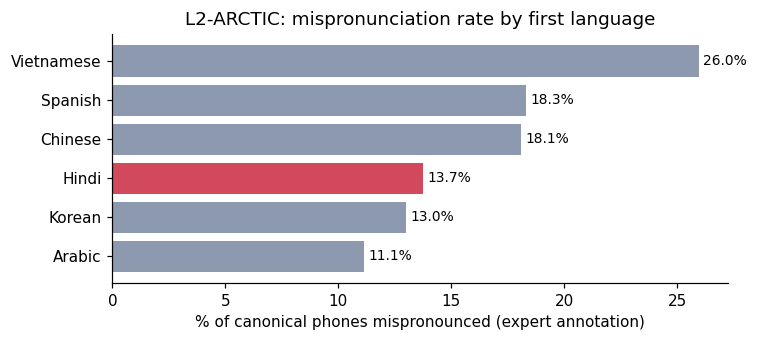

Hindi speakers: 2713 annotated errors. Top 20 ('-' = sound deleted):


,expected,produced,count,share_of_errors,has_feedback_rule
0,ð,d,250,9.2%,True
1,z,s,234,8.6%,True
2,ɝ,ʌ,114,4.2%,True
3,ɑ,ʌ,107,3.9%,False
4,eɪ,ɛ,99,3.6%,False
5,oʊ,ɔ,97,3.6%,False
6,d,-,90,3.3%,False
7,ɑ,ɔ,89,3.3%,False
8,ɹ,-,89,3.3%,False
9,θ,t,84,3.1%,True


In [6]:
rate_rows, pairs_by_l1 = [], {}
for l1, g in meta.groupby("speaker_native_language"):
    n_can = n_mis = 0
    pairs = Counter()
    for c, a in zip(g.canonical, g.annotated):
        real = pc.realised_per_canonical(c, a)
        n_can += len(c); n_mis += sum(x != y for x, y in zip(c, real))
        pairs.update(pc.error_pairs(c, a))
    rate_rows.append({"L1": l1, "speakers": g.speaker_code.nunique(), "mispronunciation_rate": n_mis / n_can})
    pairs_by_l1[l1] = pairs
rates = pd.DataFrame(rate_rows).sort_values("mispronunciation_rate")

fig, ax = plt.subplots(figsize=(7, 3.2))
colors = ["#d1495b" if l == "Hindi" else "#8d99ae" for l in rates.L1]
ax.barh(rates.L1, rates.mispronunciation_rate * 100, color=colors)
for y, v in enumerate(rates.mispronunciation_rate * 100):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of canonical phones mispronounced (expert annotation)")
ax.set_title("L2-ARCTIC: mispronunciation rate by first language")
plt.tight_layout(); plt.savefig(f"{FIG}/A1_mispronunciation_rate_by_L1.png", dpi=200); plt.show()

hp = pairs_by_l1["Hindi"]; total = sum(hp.values())
top = pd.DataFrame([{"expected": e, "produced": p, "count": n, "share_of_errors": n / total,
                     "has_feedback_rule": (e, p) in pc.FEEDBACK}
                    for (e, p), n in hp.most_common(20)])
top.to_csv(f"{RES}/A2_hindi_top_errors.csv", index=False)
print(f"Hindi speakers: {total} annotated errors. Top 20 ('-' = sound deleted):")
display(top.style.format({"share_of_errors": "{:.1%}"}))

## B. Classical speech-processing pipeline
Every step below is implemented from first principles in `phonolens_core.py`:

| Step | What it does |
|---|---|
| Pre-emphasis `y[n] = x[n] − 0.97·x[n−1]` | Flattens the ~−6 dB/octave spectral tilt so LPC models the higher formants properly |
| Energy + zero-crossing-rate VAD | Separates speech from silence (with 50 ms hangover smoothing) |
| pYIN pitch | F0 contour and voicing decision |
| **Pitch-adaptive LPC formants** | Median F0 picks the analysis ceiling (5000 / 5500 / 6500 Hz); resample to 2×ceiling; 25 ms Hamming frames; autocorrelation LPC (order 12, Levinson–Durbin); roots of A(z) give formant frequencies and bandwidths |

ASI · he was a head shorter than his companion of almost delicate physique


median F0 = 130 Hz → formant ceiling 5000 Hz


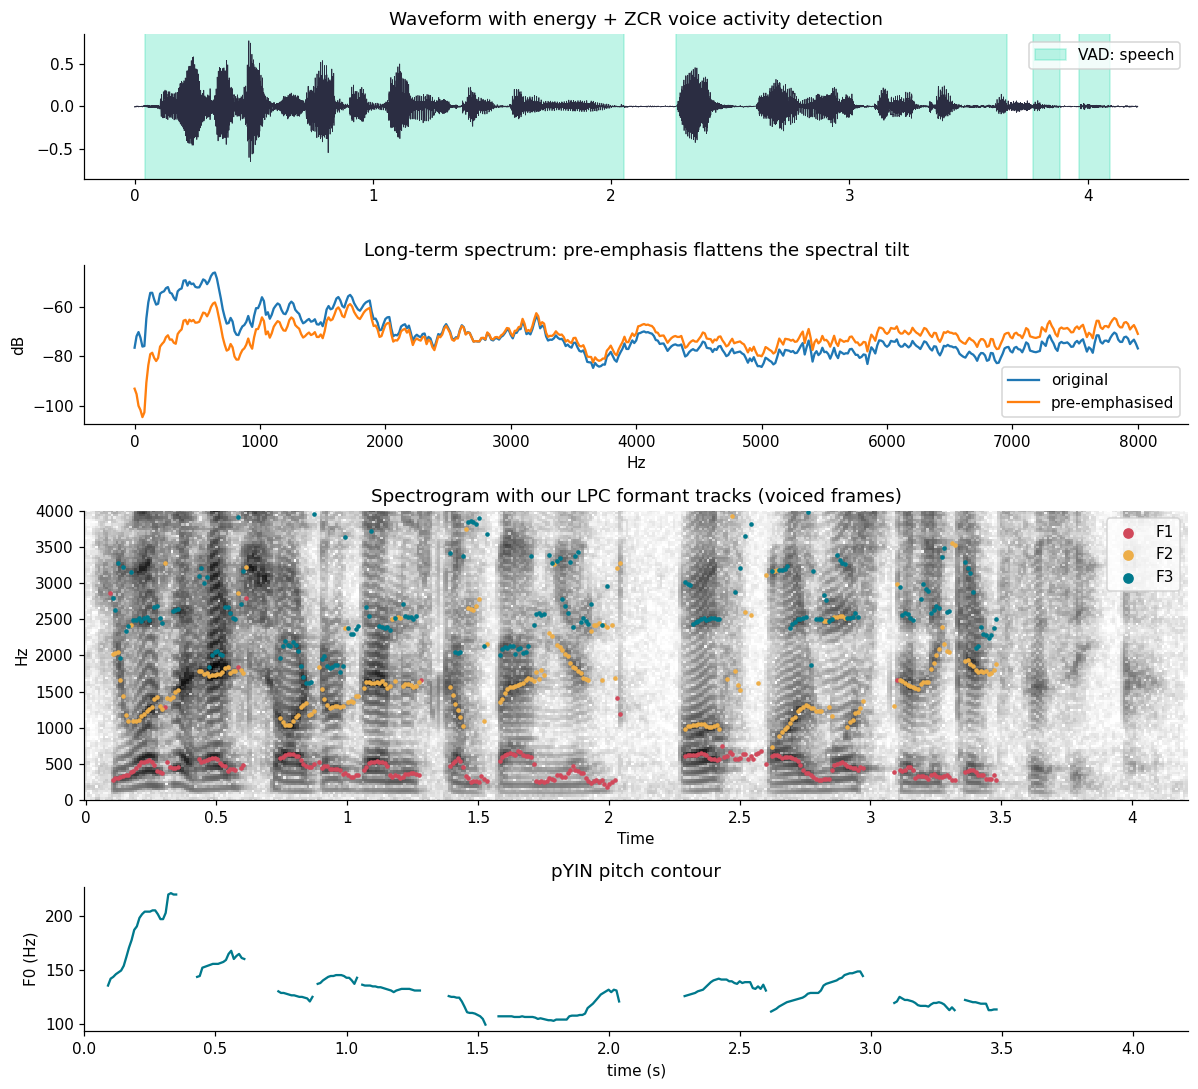

In [7]:
import librosa, librosa.display, scipy.signal as sps
from IPython.display import Audio as PlayAudio, display

SR = 16000
hindi_idx = meta.index[meta.split == "test_hindi"]
i_demo = int(hindi_idx[7])
x = np.asarray(l2[i_demo]["audio"]["array"], dtype=np.float64)
print(meta.loc[i_demo, "speaker_code"], "·", meta.loc[i_demo, "text"])
display(PlayAudio(x, rate=SR))

tt, f0, voiced = pc.pitch_track(x, SR)
f0_med = np.nanmedian(f0)
t, F, BW = pc.track_formants(x, SR, f0_med)
vf = np.interp(t, tt, voiced.astype(float)) > 0.5
speech, e_db, zcr, hop = pc.energy_zcr_vad(x, SR)
ts = (np.arange(len(speech)) * hop + 200) / SR
print(f"median F0 = {f0_med:.0f} Hz → formant ceiling {pc.formant_ceiling(f0_med):.0f} Hz")

fig, axes = plt.subplots(4, 1, figsize=(11, 10), gridspec_kw={"height_ratios": [1, 1.1, 2, 1]})
time = np.arange(len(x)) / SR
axes[0].plot(time, x, lw=0.5, color="#2b2d42")
axes[0].fill_between(ts, -1, 1, where=speech, color="#06d6a0", alpha=0.25, step="mid", label="VAD: speech")
axes[0].set_ylim(np.abs(x).max() * -1.1, np.abs(x).max() * 1.1); axes[0].legend(loc="upper right")
axes[0].set_title("Waveform with energy + ZCR voice activity detection")

for sig, lab in [(x, "original"), (pc.pre_emphasis(x), "pre-emphasised")]:
    f, P = sps.welch(sig, SR, nperseg=1024)
    axes[1].plot(f, 10 * np.log10(P + 1e-15), label=lab)
axes[1].set_xlabel("Hz"); axes[1].set_ylabel("dB"); axes[1].legend()
axes[1].set_title("Long-term spectrum: pre-emphasis flattens the spectral tilt")

S = librosa.amplitude_to_db(np.abs(librosa.stft(pc.pre_emphasis(x), n_fft=512, hop_length=160)), ref=np.max)
librosa.display.specshow(S, sr=SR, hop_length=160, x_axis="time", y_axis="hz", ax=axes[2], cmap="Greys")
for k, c in enumerate(["#d1495b", "#edae49", "#00798c"]):
    axes[2].scatter(t[vf], F[vf, k], s=4, color=c, label=f"F{k+1}")
axes[2].set_ylim(0, 4000); axes[2].legend(loc="upper right", markerscale=3)
axes[2].set_title("Spectrogram with our LPC formant tracks (voiced frames)")

axes[3].plot(tt, f0, color="#00798c"); axes[3].set_ylabel("F0 (Hz)"); axes[3].set_xlabel("time (s)")
axes[3].set_title("pYIN pitch contour"); axes[3].set_xlim(0, time[-1])
plt.tight_layout(); plt.savefig(f"{FIG}/B1_classical_pipeline.png", dpi=200); plt.show()

### Validating our LPC formant tracker against Praat
We run our tracker and Praat's Burg formant tracker (via `parselmouth`) with the same ceiling on 40 random utterances, and compare F1/F2 on voiced frames. F3+ are excluded: Praat is forced to find 5 formants and sometimes inserts a spurious one between F2 and F3, which shifts its numbering.

Praat comparison:   0%|          | 0/40 [00:00<?, ?it/s]

,formant,frames,median_abs_diff_Hz,within_10%,pearson_r
0,F1,8343,17.702,0.718,0.537
1,F2,8343,46.450,0.714,0.531


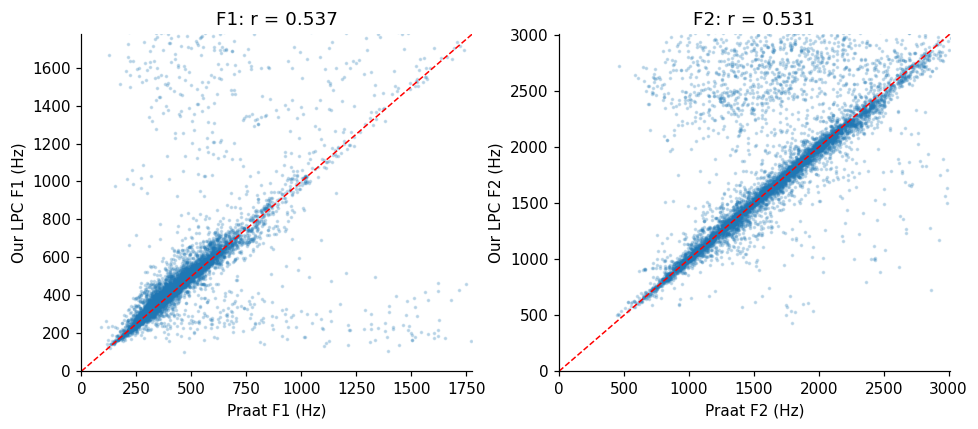

In [8]:
import parselmouth
rng = np.random.default_rng(0)
ours, praat = [], []
for i in tqdm(rng.choice(len(meta), 40, replace=False), desc="Praat comparison"):
    xi = np.asarray(l2[int(i)]["audio"]["array"], dtype=np.float64)
    tti, f0i, vi = pc.pitch_track(xi, SR)
    med = np.nanmedian(f0i) if np.any(vi) else np.nan
    ti, Fi, _ = pc.track_formants(xi, SR, med)
    m = np.interp(ti, tti, vi.astype(float)) > 0.5
    fm = parselmouth.Sound(xi, SR).to_formant_burg(time_step=0.01, max_number_of_formants=5,
                                                    maximum_formant=pc.formant_ceiling(med))
    ours.append(Fi[m][:, :2])
    praat.append(np.array([[fm.get_value_at_time(k, tk) for k in (1, 2)] for tk in ti[m]]).reshape(-1, 2))
ours, praat = np.vstack(ours), np.vstack(praat)
ok = np.all(np.isfinite(ours) & np.isfinite(praat), axis=1)
ours, praat = ours[ok], praat[ok]

val = []
for k in range(2):
    d = np.abs(ours[:, k] - praat[:, k])
    val.append({"formant": f"F{k+1}", "frames": len(d), "median_abs_diff_Hz": np.median(d),
                "within_10%": np.mean(d / praat[:, k] < 0.10),
                "pearson_r": np.corrcoef(ours[:, k], praat[:, k])[0, 1]})
val = pd.DataFrame(val); val.to_csv(f"{RES}/B2_lpc_vs_praat.csv", index=False)
display(val.round(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for k, ax in enumerate(axes):
    ax.scatter(praat[:, k], ours[:, k], s=2, alpha=0.2)
    lim = [0, np.percentile(praat[:, k], 99.5)]
    ax.plot(lim, lim, "r--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f"Praat F{k+1} (Hz)"); ax.set_ylabel(f"Our LPC F{k+1} (Hz)")
    ax.set_title(f"F{k+1}: r = {val.pearson_r[k]:.3f}")
plt.tight_layout(); plt.savefig(f"{FIG}/B2_lpc_vs_praat.png", dpi=200); plt.show()

## C. Baseline: pretrained wav2vec2 phoneme recogniser (no fine-tuning)
`facebook/wav2vec2-xlsr-53-espeak-cv-ft` was pretrained on 53 languages and fine-tuned to output espeak phonemes. Its output is normalised to our 39 phones, and then:
- **PER** (phone error rate) compares the recognised phones with the expert annotation (what was actually said)
- **MDD** (mispronunciation detection and diagnosis): a phone is *flagged* when the recognition differs from the canonical phone. Comparing flags with the expert labels gives precision, recall, F1, the false-rejection rate (correct phones wrongly flagged) and diagnosis accuracy (whether we also identified *what* was said).

Notebook 2 fine-tunes this model and should beat these numbers.

In [9]:
import torch
from transformers import Wav2Vec2ForCTC, Wav2Vec2FeatureExtractor

fe = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_DIR)
model = Wav2Vec2ForCTC.from_pretrained(MODEL_DIR).to(DEVICE).eval()
vocab = json.load(open(f"{MODEL_DIR}/vocab.json", encoding="utf-8"))
if isinstance(next(iter(vocab.values())), dict):          # some phoneme vocabs are nested per language
    vocab = next(iter(vocab.values()))
id2tok = {v: k for k, v in vocab.items()}
BLANK = model.config.pad_token_id
SPECIAL = {i for tok, i in vocab.items() if tok.startswith("<") or tok in {"|", ""}}
GROUPS, _ = pc.collapse_vocab(vocab, id2tok[BLANK])
print(f"vocab size {len(vocab)} · blank id {BLANK} · phones with no matching token:",
      [p for p, g in zip(pc.PHONES, GROUPS) if not g])

@torch.no_grad()
def run_model(model, wavs, batch_size=8):
    """Batched inference -> list of (frames, vocab) log-prob arrays (padding removed)."""
    order = np.argsort([len(w) for w in wavs])[::-1]
    out = [None] * len(wavs)
    for b in tqdm(range(0, len(order), batch_size), desc="inference"):
        idx = order[b:b + batch_size]
        batch = fe([wavs[k] for k in idx], sampling_rate=SR, return_tensors="pt", padding=True,
                   return_attention_mask=True)
        iv = batch.input_values.to(DEVICE)
        am = batch.attention_mask.to(DEVICE) if "attention_mask" in batch else None
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(iv, attention_mask=am).logits
        lp = torch.log_softmax(logits.float(), dim=-1).cpu().numpy()
        olens = model._get_feat_extract_output_lengths(torch.tensor([len(wavs[k]) for k in idx])).numpy()
        for j, k in enumerate(idx):
            out[k] = lp[j, :min(int(olens[j]), lp.shape[1])]
    return out

def decode_baseline(lp):
    ids = pc.ctc_greedy(lp.argmax(-1), blank=BLANK)
    return pc.tokens_to_phones([id2tok[i] for i in ids if i not in SPECIAL])

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

vocab size 392 · blank id 0 · phones with no matching token: []


In [10]:
eval_idx = meta.index[meta.split.isin(["test_hindi", "dev"])].tolist()
sub = l2.select(eval_idx)
wavs = [np.asarray(a["array"], dtype=np.float32) for a in tqdm(sub["audio"], desc="loading audio")]
lps = run_model(model, wavs)

ev = meta.loc[eval_idx].copy()
ev["recognised"] = [decode_baseline(lp) for lp in lps]
collapsed = [pc.collapse_log_probs(lp, GROUPS, BLANK) for lp in lps]   # (T, 40) for forced alignment

def evaluate(df, col="recognised"):
    tot = Counter()
    for c, a, r in zip(df.canonical, df.annotated, df[col]):
        tot.update(pc.mdd_counts(c, a, r))
    m = pc.mdd_metrics(tot)
    m["PER"] = pc.per(df.annotated.tolist(), df[col].tolist())
    m["utterances"] = len(df)
    return m

baseline = pd.DataFrame({name: evaluate(g) for name, g in ev.groupby("split")}).T
baseline = baseline[["utterances", "PER", "precision", "recall", "f1", "false_rejection_rate", "diagnosis_acc"]]
baseline.to_csv(f"{RES}/C1_baseline_metrics.csv")
print("Pretrained baseline (no fine-tuning):")
display(baseline.style.format({c: "{:.3f}" for c in baseline.columns if c != "utterances"}))

save = ev[["speaker_code", "speaker_native_language", "split", "text"]].copy()
for col in ["canonical", "annotated", "recognised"]:
    save[col] = ev[col].map(" ".join)
save.to_csv(f"{RES}/C1_baseline_predictions.csv")

loading audio:   0%|          | 0/1350 [00:00<?, ?it/s]

inference:   0%|          | 0/169 [00:00<?, ?it/s]

Pretrained baseline (no fine-tuning):


,utterances,PER,precision,recall,f1,false_rejection_rate,diagnosis_acc
dev,750.000000,0.256,0.466,0.581,0.517,0.150,0.600
test_hindi,600.000000,0.231,0.364,0.492,0.419,0.137,0.628


In [11]:
def show(row):
    """Canonical vs annotated vs recognised, aligned on the canonical phones."""
    ann = pc.realised_per_canonical(row.canonical, row.annotated)
    rec = pc.realised_per_canonical(row.canonical, row.recognised)
    w = [max(len(c), len(a), len(r)) + 1 for c, a, r in zip(row.canonical, ann, rec)]
    fmt = lambda seq: "".join(s.ljust(k) for s, k in zip(seq, w))
    mark = ["✗".ljust(k) if a != c else "".ljust(k) for c, a, k in zip(row.canonical, ann, w)]
    flag = ["▲".ljust(k) if r != c else "".ljust(k) for c, r, k in zip(row.canonical, rec, w)]
    print(f"[{row.speaker_code}] {row.text}")
    print("  canonical :", fmt(row.canonical))
    print("  annotated :", fmt(ann)); print("  errors    :", "".join(mark))
    print("  recognised:", fmt(rec)); print("  flagged   :", "".join(flag), "\n")

for _, r in ev[(ev.split == "test_hindi") & (ev.n_diff.between(2, 4))].head(3).iterrows():
    show(r)

[ASI] will we ever forget it
  canonical : w ɪ l w i ɛ v ɝ f ɝ ɡ ɛ  t ɪ t 
  annotated : w ɪ l w i æ w ɝ f ɹ ɡ ɛ  t ɪ t 
  errors    :           ✗ ✗     ✗            
  recognised: v ɪ l v i ɛ - ʌ f ɛ ɡ eɪ t ʌ t 
  flagged   : ▲     ▲     ▲ ▲   ▲   ▲    ▲    

[ASI] and you always want to see it in the superlative degree
  canonical : ʌ n d j u ɔ l w eɪ z w ɑ n t t u s i ɪ t ɪ n ð ʌ s ʊ p ɝ l ʌ  t ɪ v d ɪ ɡ ɹ i 
  annotated : æ n d j u ɔ l w i  z w ɑ n t t u s i ɪ t ɪ n d ʌ s ʊ p ɝ l eɪ t ɪ v d ɪ ɡ ɹ i 
  errors    : ✗               ✗                            ✗             ✗                  
  recognised: æ n d j u ɔ l w eɪ z w ɔ n t t ʊ s i ɪ t ɪ n ð ʌ s u p ɝ l eɪ t ɪ v d ɪ ɡ ɹ i 
  flagged   : ▲                      ▲       ▲                   ▲       ▲                   

[ASI] if i ever needed a fighter in my life i need one now
  canonical : ɪ f aɪ ɛ v ɝ n i d ʌ d ʌ f aɪ t ɝ ɪ n m aɪ l aɪ f aɪ n i d w ʌ n n aʊ 
  annotated : ɪ f aɪ æ w ɝ n i d ʌ d ʌ f aɪ t ɝ ɪ n m aɪ l aɪ f aɪ

In [13]:
# Patch: fix int8 overflow in ctc_forced_align, then reload the module
p = f"{SAVE}/phonolens_core.py"
src = open(p, encoding="utf-8").read()
src = src.replace("s -= back[t, s]", "s -= int(back[t, s])")
open(p, "w", encoding="utf-8").write(src)
importlib.reload(pc)
print("patched ✅" if "int(back[t, s])" in open(p).read() else "patch failed")

patched ✅


vowel formants:   0%|          | 0/200 [00:00<?, ?it/s]

/content/drive/MyDrive/phonolens_data/phonolens_core.py:476: RuntimeWarning: All-NaN slice encountered
  return np.nanmedian(F[m], axis=0)


2286 vowel tokens measured from 9 speakers


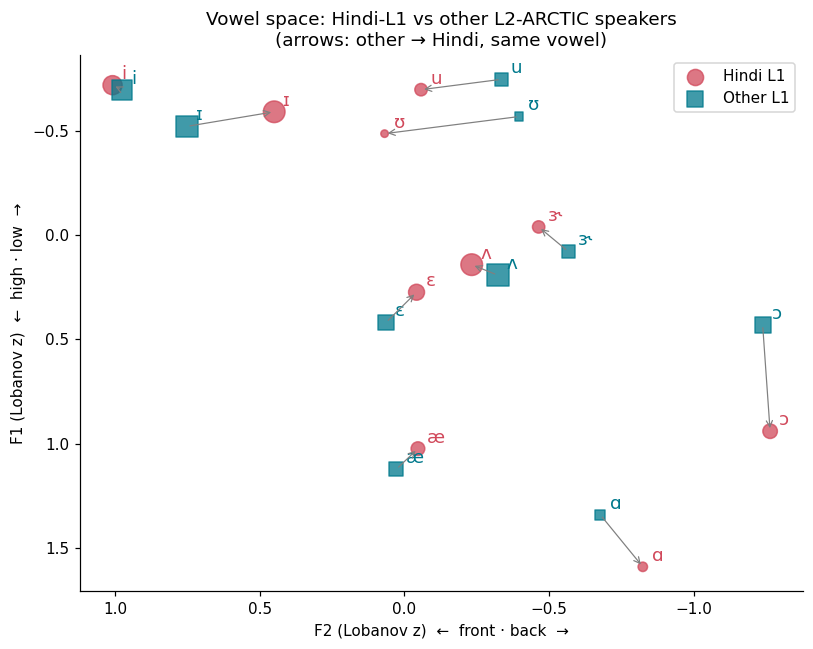

In [14]:
FRAME_S = 0.02                      # wav2vec2 outputs one frame per 20 ms
vowel_rows = []
spk_f0 = {}
pos = {i: k for k, i in enumerate(eval_idx)}
cap = {"test_hindi": 25, "dev": 20}  # utterances per speaker (keeps this ~5 min)
chosen = pd.concat([g.head(cap[g.split.iloc[0]]) for _, g in ev.groupby("speaker_code")])

for i, row in tqdm(chosen.iterrows(), total=len(chosen), desc="vowel formants"):
    k = pos[i]; xi = wavs[k].astype(np.float64)
    if row.speaker_code not in spk_f0:
        _, f0s, vs = pc.pitch_track(xi, SR)
        spk_f0[row.speaker_code] = np.nanmedian(f0s) if np.any(vs) else np.nan
    targets = [pc.PHONES.index(p) + 1 for p in row.annotated]
    spans = pc.ctc_forced_align(collapsed[k], targets, blank=0)
    if spans is None:
        continue
    ti, Fi, _ = pc.track_formants(xi, SR, spk_f0[row.speaker_code])
    for p, (s0, s1) in zip(row.annotated, spans):
        if p in pc.MONOPHTHONGS and (s1 - s0 + 1) >= 2:
            f1, f2, _ = pc.segment_formants(ti, Fi, s0 * FRAME_S, (s1 + 1) * FRAME_S)
            vowel_rows.append({"speaker": row.speaker_code, "group": "Hindi L1" if row.split == "test_hindi" else "Other L1",
                               "vowel": p, "F1": f1, "F2": f2})

vw = pd.DataFrame(vowel_rows).dropna()
vw = vw[(vw.F1.between(150, 1200)) & (vw.F2.between(500, 3500))]
vw[["zF1", "zF2"]] = vw.groupby("speaker")[["F1", "F2"]].transform(lambda s: (s - s.mean()) / s.std())
means = vw.groupby(["group", "vowel"]).agg(zF1=("zF1", "mean"), zF2=("zF2", "mean"),
                                            F1=("F1", "median"), F2=("F2", "median"), n=("F1", "size")).reset_index()
means = means[means.n >= 15]
means.to_csv(f"{RES}/D1_vowel_means.csv", index=False)
print(f"{len(vw)} vowel tokens measured from {chosen.speaker_code.nunique()} speakers")

fig, ax = plt.subplots(figsize=(7.5, 6))
style = {"Hindi L1": ("#d1495b", "o"), "Other L1": ("#00798c", "s")}
for grp, d in means.groupby("group"):
    c, m = style[grp]
    ax.scatter(d.zF2, d.zF1, s=d.n.clip(20, 200), color=c, marker=m, alpha=0.75, label=grp)
    for _, r in d.iterrows():
        ax.annotate(r.vowel, (r.zF2, r.zF1), textcoords="offset points", xytext=(6, 4), color=c, fontsize=12)
for v in set(means.vowel):
    d = means[means.vowel == v].set_index("group")
    if len(d) == 2:
        ax.annotate("", xy=(d.loc["Hindi L1", "zF2"], d.loc["Hindi L1", "zF1"]),
                    xytext=(d.loc["Other L1", "zF2"], d.loc["Other L1", "zF1"]),
                    arrowprops=dict(arrowstyle="->", color="grey", lw=0.8))
ax.invert_xaxis(); ax.invert_yaxis()
ax.set_xlabel("F2 (Lobanov z)  ←  front · back  →"); ax.set_ylabel("F1 (Lobanov z)  ←  high · low  →")
ax.set_title("Vowel space: Hindi-L1 vs other L2-ARCTIC speakers\n(arrows: other → Hindi, same vowel)")
ax.legend(); plt.tight_layout(); plt.savefig(f"{FIG}/D1_vowel_chart.png", dpi=200); plt.show()

## D. Vowel chart: where do Hindi-L1 speakers place their vowels?
1. **CTC forced alignment** (our Viterbi implementation) aligns the *annotated* phones to the audio, giving each vowel a time segment.
2. Our LPC tracker measures F1/F2 in the middle half of each segment.
3. **Lobanov normalisation** (z-score per speaker) removes vocal-tract-length differences, so male and female speakers can be compared.

F1 is related to tongue height (high F1 = open/low vowel); F2 to frontness (high F2 = front vowel).

## Summary

In [15]:
print("=== Baseline (pretrained, no fine-tuning) ===")
display(baseline.round(3))
print("\nLPC vs Praat:"); display(val.round(3))
print("\nSaved files:")
for d in (FIG, RES):
    for f in sorted(os.listdir(d)):
        print("  ", os.path.join(os.path.basename(d), f))

=== Baseline (pretrained, no fine-tuning) ===


,utterances,PER,precision,recall,f1,false_rejection_rate,diagnosis_acc
dev,750.0,0.256,0.466,0.581,0.517,0.150,0.600
test_hindi,600.0,0.231,0.364,0.492,0.419,0.137,0.628



LPC vs Praat:


,formant,frames,median_abs_diff_Hz,within_10%,pearson_r
0,F1,8343,17.702,0.718,0.537
1,F2,8343,46.450,0.714,0.531



Saved files:
   figures/A1_mispronunciation_rate_by_L1.png
   figures/B1_classical_pipeline.png
   figures/B2_lpc_vs_praat.png
   figures/D1_vowel_chart.png
   results/A2_hindi_top_errors.csv
   results/B2_lpc_vs_praat.csv
   results/C1_baseline_metrics.csv
   results/C1_baseline_predictions.csv
   results/D1_vowel_means.csv
   results/splits.json


**Next (Notebook 2):** fine-tune the recogniser on the 15 training speakers (plus the fully correct speechocean762 utterances), compare with this baseline on the unseen Hindi speakers, add GOP scoring trained on speechocean762's expert scores, build Indian-English reference norms from IndicTTS, run the Svarah accent-fairness check, and package it all into the Gradio app.